# Automated Web Security Scanner
### Secure-Header, Cookie and CORS Misconfiguration Auditor

**Author:** Suman Vyas  
**Programme:** IBM SkillsBuild Cyber Security Bootcamp 2026 | BharatCares  
**Project topic:** Automated Web Scanner - a Python script that audits sites for secure headers and CORS flaws

---

## 1. Introduction
Many real-world web breaches do not come from complex zero-days. They come from **missing or weak HTTP security controls**:
a missing `Content-Security-Policy`, a session cookie without `HttpOnly`, or a CORS policy that trusts any origin.
These issues are listed under *Security Misconfiguration* (OWASP Top 10 - A05:2021) and are easy to detect automatically.

This notebook builds a **passive/low-impact scanner** that, for each target URL:

1. Fetches the page and audits **security response headers** (HSTS, CSP, X-Frame-Options, etc.).
2. Detects **information-disclosure** headers (`Server`, `X-Powered-By`).
3. Audits **cookie flags** (`Secure`, `HttpOnly`, `SameSite`).
4. Runs **CORS probes** with crafted `Origin` headers (reflected origin, `null` origin, wildcard, suffix/prefix bypass, risky pre-flight).
5. Scores each site, ranks the findings by severity and exports **CSV / JSON / HTML** reports.

> **Ethical-use notice:** Only scan systems you own or have written permission to test.
> To make this notebook fully reproducible and 100% legal to run, it ships with a **built-in local test lab**
> (three small web servers on `127.0.0.1` - one insecure, one partially hardened, one hardened).

## 2. Setup - imports and configuration

In [1]:
import json
import re
import threading
import time
from dataclasses import dataclass, asdict
from datetime import datetime
from html import escape
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import pandas as pd
import requests
from IPython.display import display

# ----------------------------- CONFIGURATION -----------------------------
RUN_LOCAL_LAB = True            # scan the built-in local lab (safe and reproducible)
EXTRA_TARGETS = [               # add ONLY sites you own / are authorised to test, e.g. "https://example.com"
]
REQUEST_TIMEOUT = 8             # seconds
USER_AGENT = "WebSecAuditor/1.0 (educational project)"
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

SEVERITY_PENALTY = {"High": 15, "Medium": 8, "Low": 3, "Info": 0}
SEVERITY_ORDER = ["High", "Medium", "Low", "Info"]
print("Configuration loaded. Output folder:", OUTPUT_DIR.resolve().name)

Configuration loaded. Output folder: output


## 3. Data model
Every check returns a `Finding`. A finding has a *status* (`PASS` / `FAIL`), a *severity* (only meaningful when it fails),
a human-readable detail and a recommendation for the developer.

In [2]:
@dataclass
class Finding:
    target: str
    category: str        # Headers | Cookies | CORS | Transport | Disclosure
    check: str
    status: str          # PASS or FAIL
    severity: str        # High / Medium / Low / Info
    detail: str
    recommendation: str


def make_session():
    s = requests.Session()
    s.headers.update({"User-Agent": USER_AGENT})
    return s

## 4. Check module 1 - Security headers & information disclosure
Each rule is defined as *(header, severity, validator, why it matters, fix)*. The validator inspects the **value**, not just the presence,
so a weak policy such as `script-src *` or `max-age=60` is still reported.

In [3]:
def _hsts_ok(v):
    m = re.search(r"max-age=(\d+)", v, re.I)
    return bool(m) and int(m.group(1)) >= 15552000      # >= 180 days


def _csp_ok(v):
    low = v.lower()
    if "default-src" not in low and "script-src" not in low:
        return False
    # unsafe-inline / unsafe-eval / wildcard sources defeat the purpose of CSP
    return not re.search(r"(unsafe-inline|unsafe-eval|script-src[^;]*\*|default-src[^;]*\*)", low)


HEADER_RULES = [
    ("Strict-Transport-Security", "High", _hsts_ok,
     "Forces browsers to use HTTPS; prevents SSL-stripping attacks.",
     "Add: Strict-Transport-Security: max-age=31536000; includeSubDomains"),
    ("Content-Security-Policy", "High", _csp_ok,
     "Primary defence-in-depth against Cross-Site Scripting (XSS).",
     "Add a strict CSP, e.g. default-src 'self'; avoid 'unsafe-inline' and wildcards."),
    ("X-Frame-Options", "Medium", lambda v: v.strip().upper() in ("DENY", "SAMEORIGIN"),
     "Stops clickjacking by controlling who can embed the page in a frame.",
     "Add: X-Frame-Options: DENY (or use CSP frame-ancestors)."),
    ("X-Content-Type-Options", "Medium", lambda v: v.strip().lower() == "nosniff",
     "Prevents MIME-type sniffing that can turn uploads into executable scripts.",
     "Add: X-Content-Type-Options: nosniff"),
    ("Referrer-Policy", "Low", lambda v: v.strip().lower() not in ("unsafe-url", "no-referrer-when-downgrade"),
     "Limits leakage of URLs (which may hold tokens) to third parties.",
     "Add: Referrer-Policy: strict-origin-when-cross-origin"),
    ("Permissions-Policy", "Low", lambda v: len(v.strip()) > 0,
     "Restricts powerful browser features (camera, microphone, geolocation).",
     "Add: Permissions-Policy: geolocation=(), camera=(), microphone=()"),
    ("Cross-Origin-Opener-Policy", "Low", lambda v: v.strip().lower() in ("same-origin", "same-origin-allow-popups"),
     "Isolates the browsing context from cross-origin windows (Spectre-class leaks).",
     "Add: Cross-Origin-Opener-Policy: same-origin"),
]


def check_security_headers(target, resp, check_transport=True):
    out = []
    https = urlparse(resp.url).scheme == "https"
    if check_transport:
        out.append(Finding(target, "Transport", "HTTPS in use",
                           "PASS" if https else "FAIL", "High",
                           "Site is served over HTTPS." if https else "Site is served over plain HTTP; traffic can be read or modified.",
                           "Serve all content over HTTPS with a valid certificate and redirect HTTP to HTTPS."))
    for name, sev, validator, why, fix in HEADER_RULES:
        if name == "Strict-Transport-Security" and not https:
            if not check_transport:
                continue                      # HSTS is only meaningful over HTTPS
        value = resp.headers.get(name)
        if value is None:
            out.append(Finding(target, "Headers", name, "FAIL", sev, f"Header missing. {why}", fix))
        elif not validator(value):
            out.append(Finding(target, "Headers", name, "FAIL", sev, f"Weak value: '{value}'. {why}", fix))
        else:
            out.append(Finding(target, "Headers", name, "PASS", "Info", f"Present: {value}", "-"))
    return out


def check_disclosure(target, resp):
    out = []
    server = resp.headers.get("Server", "")
    leaks = bool(re.search(r"\d+\.\d+", server))
    out.append(Finding(target, "Disclosure", "Server banner",
                       "FAIL" if leaks else "PASS", "Low",
                       f"Server header reveals version: '{server}'." if leaks else f"Server header is generic or absent ('{server or 'not sent'}').",
                       "Remove version numbers from the Server header (e.g. ServerTokens Prod)."))
    xpb = resp.headers.get("X-Powered-By")
    out.append(Finding(target, "Disclosure", "X-Powered-By",
                       "FAIL" if xpb else "PASS", "Low",
                       f"Technology disclosed: '{xpb}'." if xpb else "X-Powered-By header not sent.",
                       "Disable the X-Powered-By header in the framework / web server."))
    return out

## 5. Check module 2 - Cookie attributes
Session cookies must carry `HttpOnly` (blocks JavaScript theft after XSS), `Secure` (HTTPS only) and `SameSite` (CSRF protection).

In [4]:
def check_cookies(target, resp):
    out = []
    try:
        raw_cookies = resp.raw.headers.getlist("Set-Cookie")
    except AttributeError:
        raw_cookies = [resp.headers["Set-Cookie"]] if "Set-Cookie" in resp.headers else []
    if not raw_cookies:
        out.append(Finding(target, "Cookies", "Cookies set", "PASS", "Info",
                           "No cookies were set on the landing page.", "-"))
        return out
    for c in raw_cookies:
        name = c.split("=", 1)[0].strip()
        low = c.lower()
        checks = [
            ("Secure", "secure" in low, "Medium",
             "Cookie can be sent over unencrypted HTTP.", "Add the Secure attribute."),
            ("HttpOnly", "httponly" in low, "Medium",
             "Cookie is readable by JavaScript (stealable via XSS).", "Add the HttpOnly attribute."),
            ("SameSite", "samesite=" in low, "Low",
             "No SameSite attribute; browser defaults vary and CSRF risk increases.", "Add SameSite=Lax or SameSite=Strict."),
        ]
        for attr, ok, sev, bad_msg, fix in checks:
            out.append(Finding(target, "Cookies", f"{name}: {attr}", "PASS" if ok else "FAIL", sev,
                               f"Cookie '{name}' has {attr}." if ok else f"Cookie '{name}' - {bad_msg}", fix))
    return out

## 6. Check module 3 - CORS misconfiguration probes
Cross-Origin Resource Sharing (CORS) relaxes the browser's Same-Origin Policy. A bad policy lets a **malicious website read
authenticated responses** from the victim's session. The scanner sends crafted `Origin` headers and watches the reply:

| Probe | Origin sent | Vulnerable if... |
|---|---|---|
| Reflected origin | `https://evil.example.com` | server echoes it in `Access-Control-Allow-Origin` |
| Null origin | `null` | server allows `null` (reachable from sandboxed iframes / `file://`) |
| Suffix bypass | `https://<target-host>.evil.example.com` | weak regex/`endswith` validation |
| Prefix bypass | `https://evil<target-host>` | weak regex/`startswith` validation |
| Wildcard | any | `Access-Control-Allow-Origin: *` (and especially with credentials) |
| Pre-flight | `OPTIONS` with `DELETE` | dangerous methods allowed for an untrusted origin |

In [5]:
def _cors_probe(session, url, origin, method="GET", extra_headers=None):
    headers = {"Origin": origin}
    if extra_headers:
        headers.update(extra_headers)
    return session.request(method, url, headers=headers, timeout=REQUEST_TIMEOUT, allow_redirects=False)


def check_cors(target, url, session):
    out = []
    host = urlparse(url).hostname
    evil = "https://evil.example.com"
    probes = [
        ("Reflected origin", evil),
        ("Null origin", "null"),
        ("Suffix bypass", f"https://{host}.evil.example.com"),
        ("Prefix bypass", f"https://evil{host}"),
    ]
    for label, origin in probes:
        try:
            r = _cors_probe(session, url, origin)
        except requests.RequestException as e:
            out.append(Finding(target, "CORS", label, "FAIL", "Info", f"Probe failed: {e}", "Retry the scan."))
            continue
        acao = r.headers.get("Access-Control-Allow-Origin")
        acac = r.headers.get("Access-Control-Allow-Credentials", "").lower() == "true"
        vulnerable = acao is not None and acao.strip() == origin
        if vulnerable:
            sev = "High" if acac else "Medium"
            out.append(Finding(target, "CORS", label, "FAIL", sev,
                               f"Origin '{origin}' was trusted (ACAO='{acao}', credentials={'allowed' if acac else 'not allowed'}).",
                               "Validate Origin against an exact allow-list; never reflect it blindly; never allow 'null'."))
        else:
            out.append(Finding(target, "CORS", label, "PASS", "Info",
                               f"Origin '{origin}' was not trusted (ACAO={acao!r}).", "-"))

    # Wildcard policy
    try:
        r = _cors_probe(session, url, "https://probe.example.org")
        acao = r.headers.get("Access-Control-Allow-Origin")
        acac = r.headers.get("Access-Control-Allow-Credentials", "").lower() == "true"
        if acao == "*":
            sev = "High" if acac else "Low"
            out.append(Finding(target, "CORS", "Wildcard policy", "FAIL", sev,
                               "Access-Control-Allow-Origin is '*'" + (" together with credentials." if acac else "."),
                               "Replace '*' with a specific allow-list unless the content is truly public."))
        else:
            out.append(Finding(target, "CORS", "Wildcard policy", "PASS", "Info", "No wildcard CORS policy.", "-"))
        # Vary: Origin hygiene (only relevant when ACAO is dynamic)
        if acao and acao != "*" and "origin" not in r.headers.get("Vary", "").lower():
            out.append(Finding(target, "CORS", "Vary: Origin", "FAIL", "Low",
                               "Dynamic ACAO without 'Vary: Origin' can poison shared caches.",
                               "Add 'Vary: Origin' whenever ACAO depends on the request."))
    except requests.RequestException:
        pass

    # Pre-flight
    try:
        r = _cors_probe(session, url, evil, method="OPTIONS",
                        extra_headers={"Access-Control-Request-Method": "DELETE",
                                       "Access-Control-Request-Headers": "authorization"})
        acao = r.headers.get("Access-Control-Allow-Origin")
        methods = r.headers.get("Access-Control-Allow-Methods", "")
        risky = acao in (evil, "*") and re.search(r"DELETE|PUT|PATCH", methods, re.I)
        out.append(Finding(target, "CORS", "Pre-flight (DELETE)", "FAIL" if risky else "PASS", "Medium",
                           f"Untrusted origin may use state-changing methods ({methods})." if risky
                           else "Pre-flight from an untrusted origin was rejected.",
                           "Restrict Access-Control-Allow-Methods and allowed origins on pre-flight responses."))
    except requests.RequestException:
        pass
    return out

## 7. The scanner engine
`scan_target()` runs all modules against one URL and `compute_score()` converts failures into a 0-100 score with a letter grade.

In [6]:
def scan_target(label, url, check_transport=True):
    session = make_session()
    try:
        resp = session.get(url, timeout=REQUEST_TIMEOUT, allow_redirects=False)
    except requests.RequestException as e:
        print(f"[!] Could not reach {url}: {e}")
        return []
    findings = []
    findings += check_security_headers(label, resp, check_transport)
    findings += check_disclosure(label, resp)
    findings += check_cookies(label, resp)
    findings += check_cors(label, url, session)
    return findings


def compute_score(findings):
    penalty = sum(SEVERITY_PENALTY[f.severity] for f in findings if f.status == "FAIL")
    score = max(0, 100 - penalty)
    grade = "A" if score >= 90 else "B" if score >= 80 else "C" if score >= 65 else "D" if score >= 50 else "F"
    return score, grade

## 8. Built-in test lab (three local servers)
To demonstrate the scanner without touching anyone else's infrastructure, we start three tiny web servers on `127.0.0.1`:

* **Lab-Vulnerable** - no security headers, version banners, reflected CORS with credentials, insecure cookie.
* **Lab-Partial** - some headers present, wildcard CORS, cookie missing some flags.
* **Lab-Hardened** - full header set, strict CORS allow-list, secure cookie.

In [7]:
class _BaseHandler(BaseHTTPRequestHandler):
    profile = "vulnerable"

    def log_message(self, *args):       # silence console logging
        pass

    def _send_common(self, status=200):
        p = self.profile
        origin = self.headers.get("Origin")
        self.send_response(status)
        self.send_header("Content-Type", "text/html; charset=utf-8")
        if p == "vulnerable":
            self.send_header("X-Powered-By", "PHP/5.6.40")
            self.send_header("Set-Cookie", "sessionid=abc123; Path=/")
            if origin:
                self.send_header("Access-Control-Allow-Origin", origin)           # reflects ANY origin
                self.send_header("Access-Control-Allow-Credentials", "true")
                self.send_header("Access-Control-Allow-Methods", "GET, POST, PUT, DELETE")
        elif p == "partial":
            self.send_header("X-Content-Type-Options", "nosniff")
            self.send_header("X-Frame-Options", "SAMEORIGIN")
            self.send_header("Set-Cookie", "session=xyz789; Path=/; HttpOnly")
            self.send_header("Access-Control-Allow-Origin", "*")                  # wildcard
        else:  # hardened
            self.send_header("Strict-Transport-Security", "max-age=31536000; includeSubDomains")
            self.send_header("Content-Security-Policy", "default-src 'self'; frame-ancestors 'none'")
            self.send_header("X-Frame-Options", "DENY")
            self.send_header("X-Content-Type-Options", "nosniff")
            self.send_header("Referrer-Policy", "strict-origin-when-cross-origin")
            self.send_header("Permissions-Policy", "geolocation=(), camera=(), microphone=()")
            self.send_header("Cross-Origin-Opener-Policy", "same-origin")
            self.send_header("Set-Cookie", "session=s3cr3t; Path=/; Secure; HttpOnly; SameSite=Strict")
            self.send_header("Vary", "Origin")
            if origin == "https://app.trusted.example":                           # strict allow-list
                self.send_header("Access-Control-Allow-Origin", origin)
        self.end_headers()

    def do_GET(self):
        self._send_common()
        self.wfile.write(b"<html><body><h1>Lab server</h1></body></html>")

    def do_OPTIONS(self):
        self._send_common(204)


def _make_handler(profile):
    class H(_BaseHandler):
        pass
    H.profile = profile
    if profile == "hardened":
        H.server_version = "webserver"
        H.sys_version = ""
    elif profile == "partial":
        H.server_version = "nginx/1.14.0"
        H.sys_version = ""
    return H


def start_lab():
    servers, targets = [], {}
    for name, profile in [("Lab-Vulnerable", "vulnerable"), ("Lab-Partial", "partial"), ("Lab-Hardened", "hardened")]:
        srv = ThreadingHTTPServer(("127.0.0.1", 0), _make_handler(profile))
        threading.Thread(target=srv.serve_forever, daemon=True).start()
        servers.append(srv)
        targets[name] = f"http://127.0.0.1:{srv.server_address[1]}/"
    return servers, targets


lab_servers, LAB_TARGETS = ({}, {})
if RUN_LOCAL_LAB:
    lab_servers, LAB_TARGETS = start_lab()
    for n, u in LAB_TARGETS.items():
        print(f"{n:15s} -> {u}")

Lab-Vulnerable  -> http://127.0.0.1:33659/
Lab-Partial     -> http://127.0.0.1:46201/
Lab-Hardened    -> http://127.0.0.1:44437/


## 9. Run the scan

In [8]:
all_findings, summary_rows = [], []
scan_started = datetime.now()

jobs = [(n, u, False) for n, u in LAB_TARGETS.items()]          # lab is HTTP-only -> skip transport check
jobs += [(u, u, True) for u in EXTRA_TARGETS]

for label, url, transport in jobs:
    print(f"Scanning {label} ...")
    f = scan_target(label, url, check_transport=transport)
    all_findings += f
    score, grade = compute_score(f)
    summary_rows.append({
        "Target": label, "Score": score, "Grade": grade,
        "High": sum(1 for x in f if x.status == "FAIL" and x.severity == "High"),
        "Medium": sum(1 for x in f if x.status == "FAIL" and x.severity == "Medium"),
        "Low": sum(1 for x in f if x.status == "FAIL" and x.severity == "Low"),
        "Checks run": len(f),
    })

scan_finished = datetime.now()
print(f"\nDone. {len(all_findings)} checks executed in {(scan_finished - scan_started).total_seconds():.2f}s")

Scanning Lab-Vulnerable ...
Scanning Lab-Partial ...
Scanning Lab-Hardened ...

Done. 52 checks executed in 0.03s


## 10. Results

In [9]:
df = pd.DataFrame([asdict(f) for f in all_findings])
summary = pd.DataFrame(summary_rows)
print("=== EXECUTIVE SUMMARY ===")
display(summary)

=== EXECUTIVE SUMMARY ===


,Target,Score,Grade,High,Medium,Low,Checks run
0,Lab-Vulnerable,0,F,5,5,7,18
1,Lab-Partial,59,D,1,1,6,17
2,Lab-Hardened,100,A,0,0,0,17


In [10]:
print("=== FAILED CHECKS (sorted by severity) ===")
failed = df[df.status == "FAIL"].copy()
failed["sev_rank"] = failed.severity.map({s: i for i, s in enumerate(SEVERITY_ORDER)})
failed = failed.sort_values(["target", "sev_rank"]).drop(columns="sev_rank")
display(failed[["target", "category", "check", "severity", "detail"]].reset_index(drop=True))

=== FAILED CHECKS (sorted by severity) ===


,target,category,check,severity,detail
0,Lab-Partial,Headers,Content-Security-Policy,High,Header missing. Primary defence-in-depth against Cross-Site Scripting (XSS).
1,Lab-Partial,Cookies,session: Secure,Medium,Cookie 'session' - Cookie can be sent over unencrypted HTTP.
2,Lab-Partial,Headers,Referrer-Policy,Low,Header missing. Limits leakage of URLs (which may hold tokens) to third parties.
3,Lab-Partial,Headers,Permissions-Policy,Low,"Header missing. Restricts powerful browser features (camera, microphone, geolocation)."
4,Lab-Partial,Headers,Cross-Origin-Opener-Policy,Low,Header missing. Isolates the browsing context from cross-origin windows (Spectre-class leaks).
5,Lab-Partial,Disclosure,Server banner,Low,Server header reveals version: 'nginx/1.14.0 '.
6,Lab-Partial,Cookies,session: SameSite,Low,Cookie 'session' - No SameSite attribute; browser defaults vary and CSRF risk increases.
7,Lab-Partial,CORS,Wildcard policy,Low,Access-Control-Allow-Origin is '*'.
8,Lab-Vulnerable,Headers,Content-Security-Policy,High,Header missing. Primary defence-in-depth against Cross-Site Scripting (XSS).
9,Lab-Vulnerable,CORS,Reflected origin,High,"Origin 'https://evil.example.com' was trusted (ACAO='https://evil.example.com', credentials=allowed)."


## 11. Visualisation

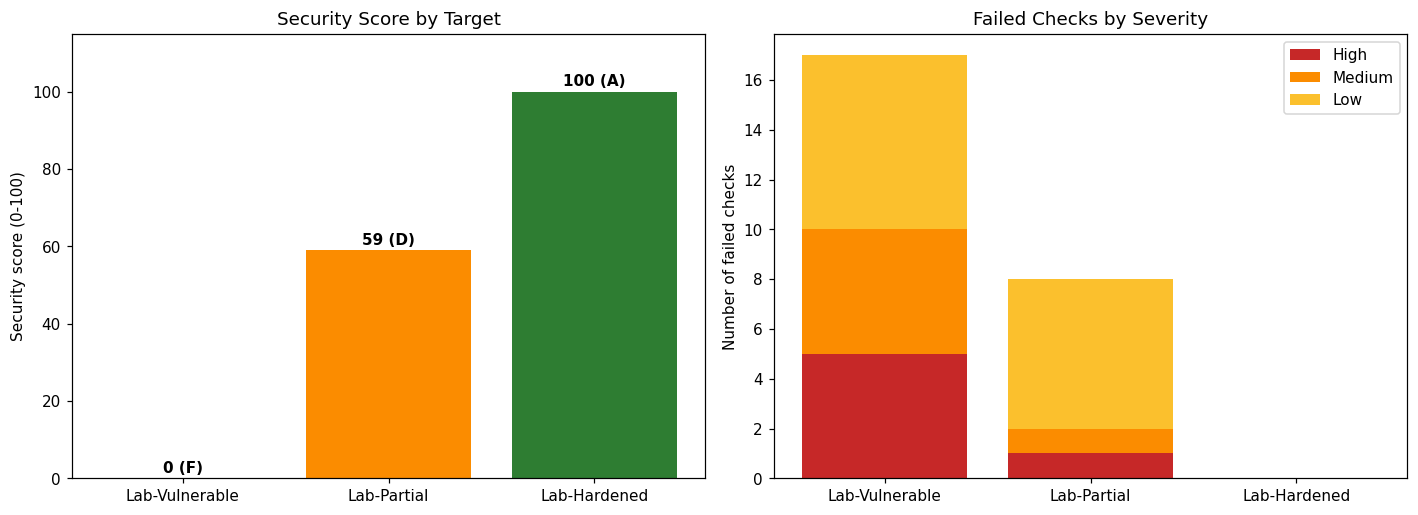

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Chart 1 - security score per target
colors = {"A": "#2e7d32", "B": "#7cb342", "C": "#fbc02d", "D": "#fb8c00", "F": "#c62828"}
axes[0].bar(summary.Target, summary.Score, color=[colors[g] for g in summary.Grade])
for i, (s, g) in enumerate(zip(summary.Score, summary.Grade)):
    axes[0].text(i, s + 1.5, f"{s} ({g})", ha="center", fontweight="bold")
axes[0].set_ylim(0, 115)
axes[0].set_ylabel("Security score (0-100)")
axes[0].set_title("Security Score by Target")

# Chart 2 - failed checks by severity (stacked)
bottom = [0] * len(summary)
for sev, col in [("High", "#c62828"), ("Medium", "#fb8c00"), ("Low", "#fbc02d")]:
    axes[1].bar(summary.Target, summary[sev], bottom=bottom, label=sev, color=col)
    bottom = [b + v for b, v in zip(bottom, summary[sev])]
axes[1].set_ylabel("Number of failed checks")
axes[1].set_title("Failed Checks by Severity")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "scan_charts.png", dpi=150)
plt.show()

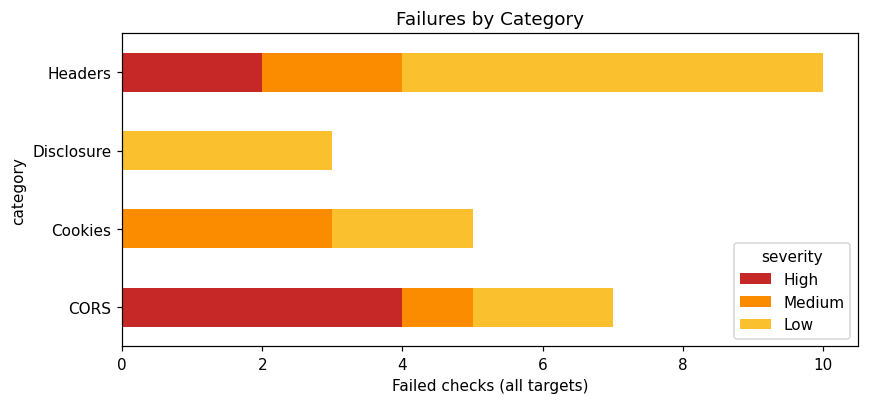

In [12]:
cat = df[df.status == "FAIL"].groupby(["category", "severity"]).size().unstack(fill_value=0)
cat = cat.reindex(columns=[s for s in SEVERITY_ORDER if s in cat.columns])
ax = cat.plot(kind="barh", stacked=True, figsize=(8, 3.8),
              color={"High": "#c62828", "Medium": "#fb8c00", "Low": "#fbc02d", "Info": "#90a4ae"})
ax.set_xlabel("Failed checks (all targets)")
ax.set_title("Failures by Category")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "category_chart.png", dpi=150)
plt.show()

## 12. Export reports
The scanner saves **CSV** (for spreadsheets), **JSON** (for automation / SIEM ingestion) and a standalone **HTML** report.

In [13]:
def build_html_report(summary_df, findings_df, started):
    rows_sum = "".join(
        f"<tr><td>{escape(str(r.Target))}</td><td>{r.Score}</td><td>{r.Grade}</td>"
        f"<td>{r.High}</td><td>{r.Medium}</td><td>{r.Low}</td></tr>" for r in summary_df.itertuples())
    sev_color = {"High": "#c62828", "Medium": "#fb8c00", "Low": "#f9a825", "Info": "#546e7a"}
    rows = ""
    for r in findings_df[findings_df.status == "FAIL"].itertuples():
        rows += (f"<tr><td>{escape(r.target)}</td><td>{escape(r.category)}</td><td>{escape(r.check)}</td>"
                 f"<td style='color:{sev_color[r.severity]};font-weight:bold'>{r.severity}</td>"
                 f"<td>{escape(r.detail)}</td><td>{escape(r.recommendation)}</td></tr>")
    return f'''<!DOCTYPE html><html><head><meta charset="utf-8"><title>Web Security Scan Report</title>
<style>body{{font-family:Segoe UI,Arial,sans-serif;margin:30px;color:#222}}
table{{border-collapse:collapse;width:100%;margin-bottom:28px}}th,td{{border:1px solid #ccc;padding:6px 9px;text-align:left;font-size:13px}}
th{{background:#1f3864;color:#fff}}h1{{color:#1f3864}}</style></head><body>
<h1>Automated Web Security Scan Report</h1><p>Generated: {started:%Y-%m-%d %H:%M:%S}</p>
<h2>Executive summary</h2><table><tr><th>Target</th><th>Score</th><th>Grade</th><th>High</th><th>Medium</th><th>Low</th></tr>{rows_sum}</table>
<h2>Failed checks</h2><table><tr><th>Target</th><th>Category</th><th>Check</th><th>Severity</th><th>Detail</th><th>Recommendation</th></tr>{rows}</table>
</body></html>'''


df.to_csv(OUTPUT_DIR / "scan_results.csv", index=False)
with open(OUTPUT_DIR / "scan_results.json", "w", encoding="utf-8") as fh:
    json.dump({"generated": scan_started.isoformat(timespec="seconds"),
               "summary": summary.to_dict(orient="records"),
               "findings": df.to_dict(orient="records")}, fh, indent=2)
(OUTPUT_DIR / "scan_report.html").write_text(build_html_report(summary, df, scan_started), encoding="utf-8")

for p in sorted(OUTPUT_DIR.iterdir()):
    print(f"saved: {p.name:22s} {p.stat().st_size:>8,d} bytes")

saved: category_chart.png       34,797 bytes
saved: scan_charts.png          57,378 bytes
saved: scan_report.html          8,244 bytes
saved: scan_results.csv          7,657 bytes
saved: scan_results.json        16,242 bytes


## 13. Validation - does the scanner behave as expected?
A good scanner must (a) rank the insecure server lowest, (b) rank the hardened server highest and (c) not raise false positives on the hardened server.
These assertions act as automated tests.

In [14]:
scores = dict(zip(summary.Target, summary.Score))
if RUN_LOCAL_LAB:
    assert scores["Lab-Vulnerable"] < scores["Lab-Partial"] < scores["Lab-Hardened"], "Ranking is wrong"
    hardened_fail = df[(df.target == "Lab-Hardened") & (df.status == "FAIL")]
    assert hardened_fail.empty, f"False positives on hardened server: {hardened_fail.check.tolist()}"
    vuln = df[(df.target == "Lab-Vulnerable") & (df.category == "CORS") & (df.status == "FAIL")]
    assert {"Reflected origin", "Null origin"} <= set(vuln.check), "CORS flaws were not detected"
    print("All validation tests PASSED")
    print("Scores:", scores)

All validation tests PASSED
Scores: {'Lab-Vulnerable': 0, 'Lab-Partial': 59, 'Lab-Hardened': 100}


In [15]:
for srv in lab_servers:
    srv.shutdown()
    srv.server_close()
print("Lab servers stopped.")

Lab servers stopped.


## 14. Conclusion
The scanner automatically detected missing/weak security headers, insecure cookies and exploitable CORS policies, produced a
score per target and exported machine-readable and human-readable reports. Validation confirmed zero false positives against
the hardened baseline and correct detection of all seeded flaws on the vulnerable server.

**Possible future work:** TLS/certificate auditing, multi-page crawling, CSV/JSON import of target lists, scheduled scans with e-mail alerts, and
SIEM (Wazuh) integration of the JSON output.

**References**
* OWASP Secure Headers Project - https://owasp.org/www-project-secure-headers/
* OWASP Top 10:2021 A05 Security Misconfiguration - https://owasp.org/Top10/A05_2021-Security_Misconfiguration/
* MDN Web Docs - CORS - https://developer.mozilla.org/docs/Web/HTTP/CORS
* PortSwigger Web Security Academy - CORS - https://portswigger.net/web-security/cors